# AMR Phase A: Cellpose (tuned) + Masked-Otsu segmentation (full dataset)
Tunes Cellpose against ground truth, segments every cell and nucleoid, saves lossless crops, tables, QC overlays and the dashboard to Drive.

**This notebook is on Segmentation.** Run it once with `MAX_IMAGES_PER_CLASS = None`. When it finishes, everything the classifiers need is on Drive (`results_final/cellpose_otsu/`). Then open **AMR_Classification.ipynb** (DenseNet121 + machine learning), which reads those saved files.

Resume-safe: finished treatment classes are skipped on re-run (`FORCE_RERUN = False`), so if the Colab session ends, just run all cells again.
For a quick test set `MAX_IMAGES_PER_CLASS = 5` (writes to `cellpose_otsu_TEST`; set `CHOOSE_TEST` in notebook 2 to match).

Dataset layout expected inside the zips: `All Images/<CLASS>/*.tif` and `All_Segments/<CLASS>/*.tif` with classes `CIP+ETOH, RIF+ETOH, GENT+ETOH, COAMOX+ETOH, WT+ETOH`.

## **0. Setup**

In [1]:
import subprocess, sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "tifffile",
        "imagecodecs",
        "cellpose<4",
        "scikit-image",
        "scipy",
        "tqdm",
        "shap",
        "lightgbm",
        "xgboost",
    ],
    check=False,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'tifffile', 'imagecodecs', 'cellpose<4', 'scikit-image', 'scipy', 'tqdm', 'shap', 'lightgbm', 'xgboost'], returncode=0)

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import io, json, random, re, shutil, sys, warnings, zipfile
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tifffile, torch
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import draw
from skimage.exposure import equalize_adapthist
from skimage.feature import blob_log, graycomatrix, graycoprops, peak_local_max
from skimage.filters import threshold_otsu, unsharp_mask
from skimage.measure import label, regionprops
from skimage.morphology import disk
from skimage.segmentation import find_boundaries, relabel_sequential, watershed
from tqdm.auto import tqdm
from cellpose import models

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

In [4]:
# =============================== SETTINGS ===============================
CLASSES = ["CIP+ETOH", "RIF+ETOH", "GENT+ETOH", "COAMOX+ETOH", "WT+ETOH"]
PIXEL_SIZE_UM = 0.065
MAX_IMAGES_PER_CLASS = None  # None = everything (full run); e.g. 5 for a quick test
FORCE_RERUN = False  # False: finished classes are skipped (resume-safe)
SEED = 42

In [5]:
# ---- Paths ----
RESEARCH = Path("/content/drive/MyDrive/Research")
RAW_ZIP = RESEARCH / "All Images.zip"
GT_ZIP = RESEARCH / "All Segments.zip"  # change if your zip is called All_Segments.zip
RAW_DIR = Path("/content/dataset_raw")
GT_RAW = Path("/content/gt_raw")
SCRATCH = Path("/content/scratch")
OUT_ROOT = (
    RESEARCH / "results_final" / ("cellpose_otsu" + ("_TEST" if MAX_IMAGES_PER_CLASS else ""))
)

In [6]:
CELLPOSE_MODEL = "bact_fluor_cp3"
AUTO_TUNE = True  # tune diameter / flow_threshold on a GT subset
RETUNE = False  # True: ignore cached tuning result on Drive
TUNE_IMAGES_PER_CLASS = (
    5  # these images are EXCLUDED from the headline (held-out) segmentation metrics
)
TUNE_SEED = 123
DIAMETER_GRID = [12, 14, 15, 16, 17, 18, 19, 20, 22, 25]
FLOW_GRID = [0.2, 0.4, 0.6, 0.8]
FALLBACK_DIAMETER, FALLBACK_FLOW = 15, 0.4  # used if AUTO_TUNE = False
CELLPROB_THRESHOLD, MIN_SIZE = 0.0, 15

In [7]:
MIN_CELL_AREA_PX = 20
NUC_MIN_AREA_PX = 10
GLCM_LEVELS = 32
QC_MIN_AREA_UM2, QC_MAX_AREA_UM2 = 0.25, 30.0

CROP_MARGIN = 4
SAVE_RAW_CROPS = True
SAVE_LABEL_CROPS = True
SAVE_PREVIEW_PNG = True
SAVE_FULL_MASKS = True
SAVE_OVERLAYS = True

ANTIBIOTIC_INFO = {
    "CIP": ("CIP", "Fluoroquinolone"),
    "RIF": ("RIF", "Rifamycin"),
    "GENT": ("GENT", "Aminoglycoside"),
    "COAMOX": ("COAMoX", "Beta-lactam combination"),
    "WT": ("None", "None"),
}
METADATA_REGEX = None
METADATA_CSV = (
    None
)
STRAIN = "MG1655"

random.seed(SEED)
np.random.seed(SEED)
UM2 = PIXEL_SIZE_UM**2
IOUS = [round(x, 2) for x in np.arange(0.50, 1.00, 0.05)]
for sub in [
    "tables/by_class",
    "metrics/by_class",
    "masks/cells",
    "masks/nucleoids",
    "overlays",
    "crops",
    "figures",
    "_markers",
]:
    (OUT_ROOT / sub).mkdir(parents=True, exist_ok=True)
print("Output folder:", OUT_ROOT)

Output folder: /content/drive/MyDrive/Research/results_final/cellpose_otsu


In [8]:
def _ok(p):
    return not p.name.startswith("._") and "__MACOSX" not in p.parts

In [9]:
RAW_DIR.mkdir(exist_ok=True)
if not any(RAW_DIR.iterdir()):
    with zipfile.ZipFile(RAW_ZIP) as z:
        z.extractall(RAW_DIR)
_hit = [p.parent for p in RAW_DIR.rglob(CLASSES[0]) if p.is_dir() and _ok(p)]
assert _hit, f"Class folder {CLASSES[0]} not found under {RAW_DIR}; check the zip layout."
INPUT_DIR = _hit[0]
print("Image root:", INPUT_DIR)
if not GT_RAW.exists():
    GT_RAW.mkdir(parents=True)
    with zipfile.ZipFile(GT_ZIP) as z:
        z.extractall(GT_RAW)
gt_index = {p.stem: p for p in GT_RAW.rglob("*.tif*") if _ok(p)}

Image root: /content/dataset_raw


In [10]:
images = {}
for cls in CLASSES:
    files = sorted(p for p in (INPUT_DIR / cls).glob("*.tif*") if _ok(p))
    images[cls] = files[:MAX_IMAGES_PER_CLASS] if MAX_IMAGES_PER_CLASS else files
print({c: len(v) for c, v in images.items()}, "| ground-truth masks:", len(gt_index))
print(
    "images without ground truth:", sum(p.stem not in gt_index for v in images.values() for p in v)
)

{'CIP+ETOH': 285, 'RIF+ETOH': 279, 'GENT+ETOH': 199, 'COAMOX+ETOH': 350, 'WT+ETOH': 455} | ground-truth masks: 1568
images without ground truth: 0


## **1. Core functions: loading, labels, evaluation**

In [11]:
def load_raw(path):
    """Native-dtype array, H x W x C. Channel 0 = Nile Red (membrane), channel 1 = DNA."""
    arr = np.squeeze(tifffile.imread(str(path)))
    if arr.ndim != 3:
        raise ValueError(f"{Path(path).name}: unsupported TIFF shape {arr.shape}")
    if arr.shape[0] <= 8 and arr.shape[1] > 32 and arr.shape[2] > 32:
        arr = np.moveaxis(arr, 0, -1)
    elif not (arr.shape[2] <= 8 and arr.shape[0] > 32 and arr.shape[1] > 32):
        raise ValueError(f"{Path(path).name}: cannot determine channel axis from {arr.shape}")
    return arr

In [12]:
def normalize_channel(ch):
    """1-99 percentile normalisation to [0,1]; used for SEGMENTATION INPUT and display only."""
    p1, p99 = np.percentile(ch, (1, 99))
    d = (p99 - p1) if p99 > p1 else 1.0
    return np.clip((ch - p1) / d, 0, 1).astype(np.float32)

In [13]:
def clean_labels(labels, min_area):
    labels = np.asarray(labels).astype(np.int64)
    if labels.max() == 0:
        return labels.astype(np.uint16)
    small = np.bincount(labels.ravel()) < min_area
    small[0] = False
    labels = np.where(small[labels], 0, labels)
    labels, _, _ = relabel_sequential(labels)
    return labels.astype(np.uint16 if labels.max() < 65535 else np.uint32)

In [14]:
def circularity(area, perimeter):
    return float(4.0 * np.pi * area / perimeter**2) if perimeter > 0 else np.nan

In [15]:
def enhance_channel(img, mask=None):
    """VIEW-ONLY: percentile stretch (inside mask) + CLAHE + mild sharpening."""
    img = img.astype(np.float32)
    vals = img[mask] if mask is not None and mask.any() else img
    p1, p99 = np.percentile(vals, (1, 99))
    if p99 <= p1:
        p99 = p1 + 1.0
    img = np.clip((img - p1) / (p99 - p1), 0, 1)
    img = equalize_adapthist(img, kernel_size=None, clip_limit=0.02)
    return np.clip(unsharp_mask(img, radius=1.0, amount=0.5), 0, 1).astype(np.float32)

In [16]:
def tiff_bytes(arr):
    buf = io.BytesIO()
    tifffile.imwrite(buf, arr, compression="zlib", photometric="minisblack")
    return buf.getvalue()

In [17]:
def png_bytes(arr_uint8):
    buf = io.BytesIO()
    Image.fromarray(arr_uint8).save(buf, format="PNG")
    return buf.getvalue()

In [18]:
def relabel(m):
    m, _, _ = relabel_sequential(np.asarray(m).astype(np.int64))
    return m

In [19]:
def analyse_pair(gt, pred):
    """TP/FP/FN at every IoU threshold (one-to-one Hungarian matching) + error decomposition.
    Split_GT: GT cell covered by >=2 pieces (each >=50% inside it). Merged_Pred: prediction holding >=50% of >=2 GT cells.
    Spurious_Pred: prediction with <10% overlap with any GT cell. Missed_GT: GT cell <10% covered.
    """
    gt, pred = relabel(gt), relabel(pred)
    n_gt, n_pred = int(gt.max()), int(pred.max())
    out = {
        "GT_Cells": n_gt,
        "Pred_Cells": n_pred,
        "GT_FG_Frac": float((gt > 0).mean()),
        "Pred_FG_Frac": float((pred > 0).mean()),
    }
    gt_area = np.bincount(gt.ravel(), minlength=n_gt + 1)[1:].astype(float)
    pred_area = np.bincount(pred.ravel(), minlength=n_pred + 1)[1:].astype(float)
    if n_gt and n_pred:
        ov = (
            np.bincount(
                gt.ravel() * (n_pred + 1) + pred.ravel(), minlength=(n_gt + 1) * (n_pred + 1)
            )
            .reshape(n_gt + 1, n_pred + 1)
            .astype(float)
        )
        inter = ov[1:, 1:]
        iou = inter / (gt_area[:, None] + pred_area[None, :] - inter)
        r, c = linear_sum_assignment(-iou)
        matched = iou[r, c]
        out["Split_GT"] = int(((inter / pred_area[None, :] >= 0.5).sum(1) >= 2).sum())
        out["Merged_Pred"] = int(((inter / gt_area[:, None] >= 0.5).sum(0) >= 2).sum())
        out["Spurious_Pred"] = int((inter.sum(0) / pred_area < 0.1).sum())
        out["Missed_GT"] = int((inter.sum(1) / gt_area < 0.1).sum())
        out["Mean_Matched_IoU@0.5"] = (
            float(matched[matched >= 0.5].mean()) if (matched >= 0.5).any() else 0.0
        )
    else:
        matched = np.array([])
        out.update(Split_GT=0, Merged_Pred=0, Spurious_Pred=n_pred, Missed_GT=n_gt)
        out["Mean_Matched_IoU@0.5"] = 0.0
    for t in IOUS:
        tp = int((matched >= t).sum())
        out[f"TP@{t}"], out[f"FP@{t}"], out[f"FN@{t}"] = tp, n_pred - tp, n_gt - tp
    return out, gt_area, pred_area

In [20]:
def pooled_scores(df):
    rows = []
    for cm, g in df.groupby("Cell_Method"):
        s = g.sum(numeric_only=True)
        row = {
            "Cell_Method": cm,
            "Images": len(g),
            "GT_Cells": int(s["GT_Cells"]),
            "Pred_Cells": int(s["Pred_Cells"]),
            "Pred/GT": s["Pred_Cells"] / s["GT_Cells"],
        }
        for t in (0.5, 0.8):
            tp, fp, fn = s[f"TP@{t}"], s[f"FP@{t}"], s[f"FN@{t}"]
            row[f"Precision@{t}"] = tp / (tp + fp) if tp + fp else np.nan
            row[f"Recall@{t}"] = tp / (tp + fn) if tp + fn else np.nan
            row[f"F1@{t}"] = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else np.nan
            row[f"Jaccard@{t}"] = tp / (tp + fp + fn) if tp + fp + fn else np.nan
        row["Split_GT_%"] = 100 * s["Split_GT"] / s["GT_Cells"]
        row["Merged_Pred_%"] = 100 * s["Merged_Pred"] / max(s["Pred_Cells"], 1)
        row["Spurious_Pred_%"] = 100 * s["Spurious_Pred"] / max(s["Pred_Cells"], 1)
        row["Missed_GT_%"] = 100 * s["Missed_GT"] / s["GT_Cells"]
        row["Segmentation_Error_Rate_%"] = 100 * (s["FP@0.5"] + s["FN@0.5"]) / s["GT_Cells"]
        row["FG_cover_ratio"] = g["Pred_FG_Frac"].mean() / g["GT_FG_Frac"].mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("Cell_Method")

In [21]:
def iou_curve(df):
    s = df.sum(numeric_only=True)
    tp, fp, fn = (np.array([s[f"{k}@{t}"] for t in IOUS], float) for k in ("TP", "FP", "FN"))
    return pd.DataFrame(
        {
            "IoU_Threshold": IOUS,
            "Jaccard": tp / (tp + fp + fn),
            "F1": 2 * tp / (2 * tp + fp + fn),
            "Precision": tp / (tp + fp),
            "Recall": tp / (tp + fn),
        }
    )

## **2. Cellpose model and tuning**

In [22]:
use_gpu = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if use_gpu else "none (CPU will be slow)")
model = models.CellposeModel(gpu=use_gpu, model_type=CELLPOSE_MODEL)

GPU: Tesla T4


100%|██████████| 25.3M/25.3M [00:01<00:00, 22.8MB/s]


In [23]:
def segment_cells(mem_norm, diameter, flow):
    masks, _, _ = model.eval(
        mem_norm,
        channels=[0, 0],
        diameter=diameter,
        min_size=MIN_SIZE,
        cellprob_threshold=CELLPROB_THRESHOLD,
        flow_threshold=flow,
    )
    return masks

In [24]:
TUNE_JSON = OUT_ROOT / "metrics" / "tuning.json"
tune_diam_df = tune_flow_df = None
tune_images = set()

In [25]:
if TUNE_JSON.exists() and not RETUNE:
    tj = json.loads(TUNE_JSON.read_text())
    DIAMETER, FLOW, tune_images = tj["diameter"], tj["flow_threshold"], set(tj["tune_images"])
    tune_diam_df, tune_flow_df = pd.DataFrame(tj["diameter_grid"]), pd.DataFrame(tj["flow_grid"])
    print(f"Loaded cached tuning: diameter={DIAMETER}, flow_threshold={FLOW}")
elif AUTO_TUNE:
    rng = random.Random(TUNE_SEED)
    names = []
    for cls in CLASSES:
        pool = sorted(p.stem for p in images[cls] if p.stem in gt_index)
        names += [(cls, n) for n in rng.sample(pool, min(TUNE_IMAGES_PER_CLASS, len(pool)))]
    items = []
    for cls, n in names:
        p = next(p for p in images[cls] if p.stem == n)
        items.append(
            (
                cls,
                n,
                normalize_channel(load_raw(p)[..., 0].astype(np.float32)),
                tifffile.imread(str(gt_index[n])),
            )
        )
    tune_images = {n for _, n in names}
    print(f"Tuning on {len(items)} images (excluded from held-out segmentation metrics)")

    def score_cfg(d, flow):
        rows = []
        for cls, n, mem_n, gt in items:
            out, _, _ = analyse_pair(
                gt, clean_labels(segment_cells(mem_n, d, flow), MIN_CELL_AREA_PX)
            )
            rows.append({"Cell_Method": "t", **out})
        r = pooled_scores(pd.DataFrame(rows)).iloc[0]
        return {
            "F1@0.5": r["F1@0.5"],
            "F1@0.8": r["F1@0.8"],
            "Pred/GT": r["Pred/GT"],
            "Split_GT_%": r["Split_GT_%"],
            "Merged_Pred_%": r["Merged_Pred_%"],
            "Spurious_Pred_%": r["Spurious_Pred_%"],
            "score": (r["F1@0.5"] + r["F1@0.8"]) / 2,
        }

    drows = [
        {"diameter": d, **score_cfg(d, FALLBACK_FLOW)} for d in tqdm(DIAMETER_GRID, desc="diameter")
    ]
    tune_diam_df = pd.DataFrame(drows)
    DIAMETER = int(tune_diam_df.loc[tune_diam_df.score.idxmax(), "diameter"])
    frows = [
        {"flow_threshold": f, **score_cfg(DIAMETER, f)}
        for f in tqdm(FLOW_GRID, desc="flow_threshold")
    ]
    tune_flow_df = pd.DataFrame(frows)
    FLOW = float(tune_flow_df.loc[tune_flow_df.score.idxmax(), "flow_threshold"])
    TUNE_JSON.write_text(
        json.dumps(
            {
                "diameter": DIAMETER,
                "flow_threshold": FLOW,
                "tune_images": sorted(tune_images),
                "diameter_grid": tune_diam_df.to_dict("records"),
                "flow_grid": tune_flow_df.to_dict("records"),
            },
            indent=2,
            default=float,
        )
    )
    tune_diam_df.to_csv(OUT_ROOT / "metrics" / "tuning_diameter.csv", index=False)
    tune_flow_df.to_csv(OUT_ROOT / "metrics" / "tuning_flow_threshold.csv", index=False)
    print(f"\nChosen: diameter={DIAMETER}, flow_threshold={FLOW}")
else:
    DIAMETER, FLOW = FALLBACK_DIAMETER, FALLBACK_FLOW
    print(f"AUTO_TUNE off: diameter={DIAMETER}, flow_threshold={FLOW}")

Tuning on 25 images (excluded from held-out segmentation metrics)


diameter:   0%|          | 0/10 [00:00<?, ?it/s]

flow_threshold:   0%|          | 0/4 [00:00<?, ?it/s]


Chosen: diameter=16, flow_threshold=0.4


In [26]:
if tune_diam_df is not None:
    display(tune_diam_df.round(3))
    display(tune_flow_df.round(3))

,diameter,F1@0.5,F1@0.8,Pred/GT,Split_GT_%,Merged_Pred_%,Spurious_Pred_%,score
0,12,0.717,0.549,1.192,5.570,0.365,21.898,0.633
1,14,0.776,0.637,1.168,3.742,0.820,19.076,0.706
2,15,0.791,0.660,1.142,3.394,1.067,17.607,0.725
3,16,0.800,0.672,1.132,3.742,0.999,16.065,0.736
4,17,0.794,0.669,1.115,3.742,1.327,14.988,0.732
5,18,0.795,0.655,1.102,3.655,1.580,15.245,0.725
6,19,0.785,0.632,1.092,3.655,2.072,14.980,0.708
7,20,0.757,0.604,1.072,3.742,2.679,15.584,0.680
8,22,0.710,0.502,1.044,4.700,3.503,15.596,0.606
9,25,0.603,0.326,1.064,12.707,4.337,13.175,0.464


,flow_threshold,F1@0.5,F1@0.8,Pred/GT,Split_GT_%,Merged_Pred_%,Spurious_Pred_%,score
0,0.2,0.760,0.683,0.884,1.480,0.591,13.976,0.721
1,0.4,0.800,0.672,1.132,3.742,0.999,16.065,0.736
2,0.6,0.783,0.643,1.251,6.789,0.974,16.562,0.713
3,0.8,0.761,0.623,1.327,9.835,0.984,16.984,0.692


## **3. Nucleoid segmentation, measurements, metadata**

In [27]:
def segment_nucleoids_otsu(cell_mask, dna_raw):
    nuc = np.zeros(cell_mask.shape, dtype=np.uint32)
    nid = 1
    for prop in regionprops(cell_mask):
        r0, c0, r1, c1 = prop.bbox
        sub_c = cell_mask[r0:r1, c0:c1] == prop.label
        sub_d = dna_raw[r0:r1, c0:c1]
        vals = sub_d[sub_c]
        if vals.size <= 20 or np.ptp(vals) <= 0:
            continue
        sub_n = ndi.binary_opening((sub_d > threshold_otsu(vals)) & sub_c, structure=disk(1))
        lab = label(sub_n)
        if lab.max() == 0:
            continue
        areas = np.bincount(lab.ravel())
        win = nuc[r0:r1, c0:c1]
        for i in np.nonzero(areas >= NUC_MIN_AREA_PX)[0]:
            if i == 0:
                continue
            win[lab == i] = nid
            nid += 1
    return nuc

In [28]:
def glcm_features(sub_memb, sub_cell):
    nan = {
        "Texture_Contrast": np.nan,
        "Texture_Correlation": np.nan,
        "Texture_Energy": np.nan,
        "Texture_Homogeneity": np.nan,
    }
    vals = sub_memb[sub_cell]
    if vals.size < 4 or vals.max() <= vals.min():
        return nan
    lo, hi = vals.min(), vals.max()
    q = np.zeros(sub_memb.shape, dtype=np.uint8)
    q[sub_cell] = 1 + np.floor((vals - lo) / (hi - lo + 1e-6) * (GLCM_LEVELS - 1)).astype(np.uint8)
    g = graycomatrix(
        q,
        distances=[1],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=GLCM_LEVELS + 1,
        symmetric=True,
        normed=False,
    )[1:, 1:]
    sums = g.sum(axis=(0, 1), keepdims=True).astype(np.float64)
    if sums.sum() == 0:
        return nan
    g = g / np.where(sums == 0, 1, sums)
    return {
        "Texture_Contrast": float(graycoprops(g, "contrast").mean()),
        "Texture_Correlation": float(graycoprops(g, "correlation").mean()),
        "Texture_Energy": float(graycoprops(g, "energy").mean()),
        "Texture_Homogeneity": float(graycoprops(g, "homogeneity").mean()),
    }

In [29]:
def intensity_stats(px, prefix):
    px = px.astype(np.float64)
    return {
        f"{prefix}_Mean": px.mean(),
        f"{prefix}_Median": float(np.median(px)),
        f"{prefix}_Min": px.min(),
        f"{prefix}_Max": px.max(),
        f"{prefix}_Std": px.std(),
        f"{prefix}_Variance": px.var(),
        f"{prefix}_Sum": px.sum(),
    }

In [30]:
NUC_KEYS = [
    "Count",
    "Total_Area_um2",
    "Mean_Length_um",
    "Mean_Width_um",
    "Mean_Circularity",
    "Mean_Eccentricity",
    "Mean_DNA_Intensity",
    "Max_DNA_Intensity",
    "Integrated_DNA_Intensity",
    "Cell_Area_Ratio",
    "Contrast",
    "Offset_Frac",
    "Max_Separation_um",
]

In [31]:
def nucleoid_summary(props, sub_nuc, sub_cell, sub_dna, cell, cell_area_px, y0, x0):
    if len(props) == 0:
        out = {f"Nuc_{k}": np.nan for k in NUC_KEYS}
        out.update(
            Nuc_Count=0,
            Nuc_Total_Area_um2=0.0,
            Nuc_Cell_Area_Ratio=0.0,
            Nuc_Integrated_DNA_Intensity=0.0,
        )
        return out
    total_px = float(sum(p.area for p in props))
    nuc_pix = sub_nuc > 0
    rest = sub_cell & ~nuc_pix
    contrast = (
        (float(sub_dna[nuc_pix].mean()) / float(sub_dna[rest].mean()))
        if rest.any() and sub_dna[rest].mean() > 0
        else np.nan
    )
    cy, cx = cell.centroid[0] - y0, cell.centroid[1] - x0
    ny = sum(p.area * p.centroid[0] for p in props) / total_px
    nx = sum(p.area * p.centroid[1] for p in props) / total_px
    half = max(cell.major_axis_length / 2.0, 1e-6)
    cents = np.array([p.centroid for p in props])
    sep = (
        float(
            np.max(
                np.hypot(
                    cents[:, None, 0] - cents[None, :, 0], cents[:, None, 1] - cents[None, :, 1]
                )
            )
        )
        * PIXEL_SIZE_UM
        if len(props) > 1
        else 0.0
    )
    return {
        "Nuc_Count": len(props),
        "Nuc_Total_Area_um2": total_px * UM2,
        "Nuc_Mean_Length_um": float(np.mean([p.major_axis_length for p in props])) * PIXEL_SIZE_UM,
        "Nuc_Mean_Width_um": float(np.mean([p.minor_axis_length for p in props])) * PIXEL_SIZE_UM,
        "Nuc_Mean_Circularity": float(
            np.nanmean([circularity(p.area, p.perimeter) for p in props])
        ),
        "Nuc_Mean_Eccentricity": float(np.mean([p.eccentricity for p in props])),
        "Nuc_Mean_DNA_Intensity": float(np.mean([p.mean_intensity for p in props])),
        "Nuc_Max_DNA_Intensity": float(np.max([p.max_intensity for p in props])),
        "Nuc_Integrated_DNA_Intensity": float(sub_dna[nuc_pix].sum()),
        "Nuc_Cell_Area_Ratio": total_px / cell_area_px if cell_area_px > 0 else np.nan,
        "Nuc_Contrast": contrast,
        "Nuc_Offset_Frac": float(np.hypot(ny - cy, nx - cx) / half),
        "Nuc_Max_Separation_um": sep,
    }

In [32]:
def parse_metadata(fname, cls):
    prefix = cls.split("+")[0]
    abx, abx_class = ANTIBIOTIC_INFO.get(prefix, (prefix, ""))
    meta = {
        "Strain": STRAIN,
        "Treatment": cls,
        "Antibiotic": abx,
        "Antibiotic_Class": abx_class,
        "Pixel_Size_um": PIXEL_SIZE_UM,
        "Experiment_ID": "",
        "Antibiotic_Concentration": "",
        "Exposure_Time": "",
        "Replicate": "",
        "Microscope": "",
    }
    if METADATA_REGEX:
        m = re.search(METADATA_REGEX, fname)
        if m:
            meta.update({k: v for k, v in m.groupdict().items() if v is not None})
    return meta

## **4. Per-image processing**

In [33]:
def process_image(cls, fpath, zf, dirs):
    fname = fpath.stem
    arr = load_raw(fpath)
    H, W = arr.shape[:2]
    membrane, dna = arr[..., 0].astype(np.float32), arr[..., 1].astype(np.float32)
    mem_n, dna_n = normalize_channel(membrane), normalize_channel(dna)
    cell_mask = clean_labels(segment_cells(mem_n, DIAMETER, FLOW), MIN_CELL_AREA_PX)
    nuc_mask = segment_nucleoids_otsu(cell_mask, dna)
    meta = parse_metadata(fname, cls)

    if SAVE_FULL_MASKS:
        tifffile.imwrite(
            str(dirs["cells"] / f"{fname}_cellmask.tif"),
            cell_mask.astype(np.uint16),
            compression="zlib",
        )
        tifffile.imwrite(
            str(dirs["nucs"] / f"{fname}_nucmask.tif"),
            nuc_mask.astype(np.uint16),
            compression="zlib",
        )
    if SAVE_OVERLAYS:
        rgb = (np.stack([mem_n, dna_n, np.zeros_like(dna_n)], -1) * 255).astype(np.uint8)
        rgb[find_boundaries(cell_mask, mode="outer")] = (255, 255, 0)
        rgb[find_boundaries(nuc_mask > 0, mode="inner") & (cell_mask > 0)] = (0, 255, 255)
        Image.fromarray(rgb).save(dirs["ovl"] / f"{fname}.png")

    cell_rows, nuc_rows = [], []
    for cell in regionprops(cell_mask):
        cid = cell.label
        uid = f"{fname}_cell_{cid}"
        r0, c0, r1, c1 = cell.bbox
        y0, x0, y1, x1 = (
            max(0, r0 - CROP_MARGIN),
            max(0, c0 - CROP_MARGIN),
            min(H, r1 + CROP_MARGIN),
            min(W, c1 + CROP_MARGIN),
        )
        win = (slice(y0, y1), slice(x0, x1))
        sub_cell = cell_mask[win] == cid
        sub_memb, sub_dna = membrane[win], dna[win]
        sub_nuc = np.where(sub_cell, nuc_mask[win], 0)
        paths = {"Raw_Crop_Path": "", "Label_Crop_Path": "", "Preview_Path": ""}
        if (
            SAVE_RAW_CROPS
        ):  # ORIGINAL dtype, unmodified pixel values, both channels, lossless compression
            paths["Raw_Crop_Path"] = f"raw/{uid}.tif"
            zf.writestr(
                paths["Raw_Crop_Path"],
                tiff_bytes(np.ascontiguousarray(np.moveaxis(arr[win][..., :2], -1, 0))),
            )
        if SAVE_LABEL_CROPS:
            paths["Label_Crop_Path"] = f"labels/{uid}.tif"
            zf.writestr(
                paths["Label_Crop_Path"],
                tiff_bytes(np.stack([sub_cell.astype(np.uint16), sub_nuc.astype(np.uint16)])),
            )
        if SAVE_PREVIEW_PNG:
            rgb = np.zeros((*sub_cell.shape, 3), np.float32)
            rgb[..., 0] = enhance_channel(sub_memb, sub_cell) * sub_cell
            rgb[..., 1] = enhance_channel(sub_dna, sub_cell) * sub_cell
            paths["Preview_Path"] = f"preview/{uid}.png"
            zf.writestr(
                paths["Preview_Path"], png_bytes((np.clip(rgb, 0, 1) * 255).astype(np.uint8))
            )

        area_px = float(cell.area)
        lp, wp = float(cell.major_axis_length), float(cell.minor_axis_length)
        row = {
            "Cell_UID": uid,
            "Image_ID": fname,
            "Cell_Label": int(cid),
            **meta,
            "Treatment_Class": cls,
            "Segmentation": "cellpose+masked_otsu",
            "Cellpose_Diameter": DIAMETER,
            "Cellpose_Flow_Threshold": FLOW,
            "Touches_Border": bool(r0 == 0 or c0 == 0 or r1 == H or c1 == W),
            "Area_px": area_px,
            "Area_um2": area_px * UM2,
            "Length_px": lp,
            "Length_um": lp * PIXEL_SIZE_UM,
            "Width_px": wp,
            "Width_um": wp * PIXEL_SIZE_UM,
            "Perimeter_um": float(cell.perimeter) * PIXEL_SIZE_UM,
            "Aspect_Ratio": lp / wp if wp > 0 else np.nan,
            "Circularity": circularity(area_px, cell.perimeter),
            "Eccentricity": float(cell.eccentricity),
            "Solidity": float(cell.solidity),
            "Extent": float(cell.extent),
            "Orientation_deg": float(np.degrees(cell.orientation)),
            "Centroid_Y_px": float(cell.centroid[0]),
            "Centroid_X_px": float(cell.centroid[1]),
            "Crop_Y0": y0,
            "Crop_X0": x0,
            "Crop_Y1": y1,
            "Crop_X1": x1,
            "Image_H": H,
            "Image_W": W,
            "Raw_dtype": str(arr.dtype),
        }
        row.update(intensity_stats(sub_memb[sub_cell], "NileRed_Intensity"))
        row.update(intensity_stats(sub_dna[sub_cell], "DNA_Intensity"))
        row.update(glcm_features(sub_memb, sub_cell))
        props = regionprops(sub_nuc, intensity_image=sub_dna)
        row.update(nucleoid_summary(props, sub_nuc, sub_cell, sub_dna, cell, area_px, y0, x0))
        row["QC_Border"] = row["Touches_Border"]
        row["QC_Size_Outlier"] = bool(
            row["Area_um2"] < QC_MIN_AREA_UM2 or row["Area_um2"] > QC_MAX_AREA_UM2
        )
        row["QC_No_Nucleoid"] = row["Nuc_Count"] == 0
        row["QC_Pass"] = not (row["QC_Border"] or row["QC_Size_Outlier"])
        row.update(paths)
        row["Crop_Zip"] = f"crops_{cls}.zip"
        cell_rows.append(row)

        cy, cx = cell.centroid[0] - y0, cell.centroid[1] - x0
        th = cell.orientation
        half = max(lp / 2.0, 1e-6)
        for k, p in enumerate(props, start=1):
            ay = (p.centroid[0] - cy) * np.cos(th) + (p.centroid[1] - cx) * np.sin(th)
            nuc_rows.append(
                {
                    "Nucleoid_UID": f"{uid}_nuc_{k}",
                    "Cell_UID": uid,
                    "Image_ID": fname,
                    "Treatment_Class": cls,
                    "Area_px": float(p.area),
                    "Area_um2": p.area * UM2,
                    "Length_um": p.major_axis_length * PIXEL_SIZE_UM,
                    "Width_um": p.minor_axis_length * PIXEL_SIZE_UM,
                    "Circularity": circularity(p.area, p.perimeter),
                    "Eccentricity": float(p.eccentricity),
                    "Solidity": float(p.solidity),
                    "Mean_DNA_Intensity": float(p.mean_intensity),
                    "Max_DNA_Intensity": float(p.max_intensity),
                    "Integrated_DNA_Intensity": float(p.mean_intensity * p.area),
                    "Axis_Position": float(
                        ay / half
                    ),  # -1..1 along the cell's long axis (0 = cell centre)
                    "Centroid_Y_px": y0 + float(p.centroid[0]),
                    "Centroid_X_px": x0 + float(p.centroid[1]),
                }
            )
    return cell_rows, nuc_rows, cell_mask

## **5. Main run (one treatment class at a time, saved to Drive after each)**

In [34]:
def is_complete(cls):
    return (OUT_ROOT / "_markers" / f"{cls}.json").exists()

In [35]:
run_log = []
for cls in CLASSES:
    if is_complete(cls) and not FORCE_RERUN:
        print(f"[{cls}] already complete -> skipped")
        continue
    sc = SCRATCH / cls
    shutil.rmtree(sc, ignore_errors=True)
    dirs = {"cells": sc / "masks_cells", "nucs": sc / "masks_nucs", "ovl": sc / "overlays"}
    for d in dirs.values():
        d.mkdir(parents=True)
    zip_path = sc / f"crops_{cls}.zip"
    zf = zipfile.ZipFile(zip_path, "w", zipfile.ZIP_STORED)
    cell_rows, nuc_rows, eval_rows, gt_areas, failed = [], [], [], [], []
    for fpath in tqdm(images[cls], desc=cls):
        try:
            c_rows, n_rows, cell_mask = process_image(cls, fpath, zf, dirs)
            cell_rows += c_rows
            nuc_rows += n_rows
            gp = gt_index.get(fpath.stem)
            if gp is not None:
                gt = tifffile.imread(str(gp))
                if gt.shape == cell_mask.shape:
                    out, ga, _ = analyse_pair(gt, cell_mask)
                    eval_rows.append(
                        {
                            "Cell_Method": "cellpose_tuned",
                            "Treatment_Class": cls,
                            "Image_ID": fpath.stem,
                            "Used_For_Tuning": fpath.stem in tune_images,
                            **out,
                        }
                    )
                    gt_areas.append(ga)
        except Exception as exc:
            failed.append({"Image": str(fpath), "Error": f"{type(exc).__name__}: {exc}"})
            print(f"  ERROR {fpath.name}: {exc}")
    zf.close()
    pd.DataFrame(cell_rows).to_csv(OUT_ROOT / "tables/by_class" / f"cells_{cls}.csv", index=False)
    pd.DataFrame(nuc_rows).to_csv(
        OUT_ROOT / "tables/by_class" / f"nucleoids_{cls}.csv", index=False
    )
    pd.DataFrame(eval_rows).to_csv(OUT_ROOT / "metrics/by_class" / f"eval_{cls}.csv", index=False)
    np.save(
        OUT_ROOT / "metrics/by_class" / f"gt_areas_px_{cls}.npy",
        np.concatenate(gt_areas) if gt_areas else np.array([]),
    )
    pd.DataFrame(failed).to_csv(OUT_ROOT / "metrics/by_class" / f"failed_{cls}.csv", index=False)
    (OUT_ROOT / "masks/cells" / cls).mkdir(parents=True, exist_ok=True)
    (OUT_ROOT / "masks/nucleoids" / cls).mkdir(parents=True, exist_ok=True)
    shutil.copytree(dirs["cells"], OUT_ROOT / "masks/cells" / cls, dirs_exist_ok=True)
    shutil.copytree(dirs["nucs"], OUT_ROOT / "masks/nucleoids" / cls, dirs_exist_ok=True)
    shutil.copytree(dirs["ovl"], OUT_ROOT / "overlays" / cls, dirs_exist_ok=True)
    shutil.copy(zip_path, OUT_ROOT / "crops" / zip_path.name)
    (OUT_ROOT / "_markers" / f"{cls}.json").write_text(
        json.dumps(
            {
                "class": cls,
                "cells": len(cell_rows),
                "nucleoids": len(nuc_rows),
                "failed": len(failed),
                "finished_at": datetime.now().isoformat(),
            }
        )
    )
    shutil.rmtree(sc, ignore_errors=True)
    run_log.append(
        {
            "Class": cls,
            "Images": len(images[cls]),
            "Cells": len(cell_rows),
            "Nucleoids": len(nuc_rows),
            "Failed": len(failed),
        }
    )
display(pd.DataFrame(run_log)) if run_log else print("Nothing new processed.")

CIP+ETOH:   0%|          | 0/285 [00:00<?, ?it/s]

RIF+ETOH:   0%|          | 0/279 [00:00<?, ?it/s]

GENT+ETOH:   0%|          | 0/199 [00:00<?, ?it/s]

COAMOX+ETOH:   0%|          | 0/350 [00:00<?, ?it/s]

WT+ETOH:   0%|          | 0/455 [00:00<?, ?it/s]

,Class,Images,Cells,Nucleoids,Failed
0,CIP+ETOH,285,18490,18819,0
1,RIF+ETOH,279,25212,28840,0
2,GENT+ETOH,199,11826,13796,0
3,COAMOX+ETOH,350,9397,14470,0
4,WT+ETOH,455,26192,37375,0


## **6. Combine tables and save run configuration**

In [36]:
T = OUT_ROOT / "tables"
M = OUT_ROOT / "metrics"
cells_all = pd.concat(
    [
        pd.read_csv(T / "by_class" / f"cells_{c}.csv")
        for c in CLASSES
        if (T / "by_class" / f"cells_{c}.csv").exists()
    ],
    ignore_index=True,
)

In [37]:
nucs_all = pd.concat(
    [
        pd.read_csv(T / "by_class" / f"nucleoids_{c}.csv")
        for c in CLASSES
        if (T / "by_class" / f"nucleoids_{c}.csv").exists()
    ],
    ignore_index=True,
)

In [38]:
eval_all = pd.concat(
    [
        pd.read_csv(M / "by_class" / f"eval_{c}.csv")
        for c in CLASSES
        if (M / "by_class" / f"eval_{c}.csv").exists()
    ],
    ignore_index=True,
)

In [39]:
gt_areas_all = np.concatenate(
    [
        np.load(M / "by_class" / f"gt_areas_px_{c}.npy")
        for c in CLASSES
        if (M / "by_class" / f"gt_areas_px_{c}.npy").exists()
    ]
)

In [40]:
if METADATA_CSV:
    extra = pd.read_csv(METADATA_CSV)
    cells_all = cells_all.drop(
        columns=[c for c in extra.columns if c in cells_all.columns and c != "Image_ID"]
    ).merge(extra, on="Image_ID", how="left")

In [41]:
cells_all.to_csv(T / "cells_all.csv", index=False)

In [42]:
nucs_all.to_csv(T / "nucleoids_all.csv", index=False)

In [43]:
eval_all.to_csv(M / "per_image_evaluation.csv", index=False)

In [44]:
img_sum = (
    cells_all.groupby(["Treatment_Class", "Image_ID"])
    .agg(
        Cells=("Cell_UID", "count"),
        Border_Cells=("Touches_Border", "sum"),
        Mean_Area_um2=("Area_um2", "mean"),
        Mean_Length_um=("Length_um", "mean"),
        Mean_Width_um=("Width_um", "mean"),
        Mean_Aspect_Ratio=("Aspect_Ratio", "mean"),
        Nucleoids=("Nuc_Count", "sum"),
        Mean_Nuc_Per_Cell=("Nuc_Count", "mean"),
    )
    .reset_index()
)

In [45]:
img_sum = img_sum.merge(
    eval_all[
        [
            "Image_ID",
            "Used_For_Tuning",
            "GT_Cells",
            "Pred_Cells",
            "TP@0.5",
            "FP@0.5",
            "FN@0.5",
            "TP@0.8",
            "FP@0.8",
            "FN@0.8",
            "Mean_Matched_IoU@0.5",
        ]
    ],
    on="Image_ID",
    how="left",
)

In [46]:
img_sum.to_csv(T / "image_summary.csv", index=False)

qc = cells_all[cells_all.QC_Pass]
treat = (
    qc.groupby("Treatment_Class")
    .agg(
        Cells=("Cell_UID", "count"),
        **{
            f"{c}_{s}": (c, s)
            for c in [
                "Area_um2",
                "Length_um",
                "Width_um",
                "Aspect_Ratio",
                "Circularity",
                "Nuc_Count",
                "Nuc_Cell_Area_Ratio",
                "DNA_Intensity_Mean",
                "NileRed_Intensity_Mean",
            ]
            for s in ("mean", "median", "std")
        },
    )
    .reset_index()
)

In [47]:
treat.to_csv(T / "treatment_summary.csv", index=False)

held = eval_all[~eval_all.Used_For_Tuning]
score_heldout, score_all = pooled_scores(held), pooled_scores(eval_all)
score_heldout.round(4).to_csv(M / "scores_heldout.csv")
score_all.round(4).to_csv(M / "scores_all_images.csv")
curve = iou_curve(held)
curve.round(4).to_csv(M / "iou_curve_heldout.csv", index=False)
by_class_scores = pd.concat(
    {
        c: pooled_scores(held[held.Treatment_Class == c])
        for c in CLASSES
        if (held.Treatment_Class == c).any()
    },
    names=["Treatment_Class"],
).reset_index(level=1, drop=True)
by_class_scores.round(4).to_csv(M / "scores_by_class_heldout.csv")

In [48]:
cfg = {
    "created_at": datetime.now().isoformat(),
    "pipeline": "cellpose + masked_otsu",
    "cellpose_model": CELLPOSE_MODEL,
    "diameter": DIAMETER,
    "flow_threshold": FLOW,
    "cellprob_threshold": CELLPROB_THRESHOLD,
    "min_size": MIN_SIZE,
    "channel_used_for_cells": "membrane (Nile Red) only",
    "min_cell_area_px": MIN_CELL_AREA_PX,
    "nuc_min_area_px": NUC_MIN_AREA_PX,
    "pixel_size_um": PIXEL_SIZE_UM,
    "crop_margin_px": CROP_MARGIN,
    "tuning_images": sorted(tune_images),
    "classes": CLASSES,
    "seed": SEED,
    "iou_thresholds": IOUS,
    "versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "torch": torch.__version__,
        "tifffile": tifffile.__version__,
    },
    "notes": "Raw crops keep the original dtype and values (lossless zlib TIFF). Enhanced PNG previews are for viewing only. Intensities/texture use RAW channels.",
}

In [49]:
(OUT_ROOT / "run_configuration.json").write_text(json.dumps(cfg, indent=2, default=str))
(OUT_ROOT / "README.txt").write_text(
    """AMR final pipeline: Cellpose + masked Otsu (+ deep_learning/ for the R/S classifier)
tables/cells_all.csv           one row per cell (morphology, intensity, texture, nucleoid summary, QC flags, crop paths + bounding boxes)
tables/nucleoids_all.csv       one row per nucleoid, linked to cells by Cell_UID
tables/image_summary.csv       one row per image (+ ground-truth TP/FP/FN)
tables/treatment_summary.csv   per-treatment statistics (QC-pass cells)
tables/by_class/               per-class copies (used for resume)
crops/crops_<class>.zip        raw/<Cell_UID>.tif    2-channel (Nile Red, DNA) crop, ORIGINAL dtype, lossless
                               labels/<Cell_UID>.tif 2-channel uint16: [cell mask 0/1, nucleoid labels]
                               preview/<Cell_UID>.png enhanced RGB for viewing only (red = Nile Red, green = DNA)
masks/cells|nucleoids/<class>/ full-image uint16 label masks (lossless)
overlays/<class>/              QC overlays (yellow = cell outline, cyan = nucleoid outline)
metrics/                       ground-truth evaluation (held-out headline), tuning log
figures/dashboard.png|pdf      single summary figure
deep_learning/                 models (.keras), metrics, individual + grid figures, Grad-CAM, SHAP, predictions
Crop location of any cell in its source image: Crop_Y0:Crop_Y1, Crop_X0:Crop_X1 (columns in cells_all.csv).
"""
)
print(
    "Cells:",
    len(cells_all),
    "| Nucleoids:",
    len(nucs_all),
    "| images evaluated:",
    len(eval_all),
    f"(held-out: {len(held)})",
)
display(score_heldout.T.round(3))

Cells: 91117 | Nucleoids: 113300 | images evaluated: 1568 (held-out: 1543)


Cell_Method,cellpose_tuned
Images,1543.000
GT_Cells,83442.000
Pred_Cells,89816.000
Pred/GT,1.076
Precision@0.5,0.819
Recall@0.5,0.881
F1@0.5,0.849
Jaccard@0.5,0.737
Precision@0.8,0.689
Recall@0.8,0.742


## **7. Ground-truth results (held-out images only)**

In [50]:
display(
    by_class_scores[
        [
            "Images",
            "GT_Cells",
            "Pred_Cells",
            "Pred/GT",
            "Precision@0.5",
            "Recall@0.5",
            "F1@0.5",
            "F1@0.8",
            "Split_GT_%",
            "Merged_Pred_%",
            "Spurious_Pred_%",
            "Missed_GT_%",
        ]
    ].round(3)
)

,Images,GT_Cells,Pred_Cells,Pred/GT,Precision@0.5,Recall@0.5,F1@0.5,F1@0.8,Split_GT_%,Merged_Pred_%,Spurious_Pred_%,Missed_GT_%
Treatment_Class,,,,,,,,,,,,
CIP+ETOH,280,16339,18354,1.123,0.784,0.881,0.830,0.688,3.152,1.095,14.460,4.449
RIF+ETOH,274,23314,24879,1.067,0.829,0.885,0.856,0.711,3.165,1.150,9.538,4.444
GENT+ETOH,194,11261,11688,1.038,0.894,0.928,0.910,0.829,2.362,0.565,5.544,3.179
COAMOX+ETOH,345,8729,9287,1.064,0.796,0.846,0.820,0.639,2.704,0.280,12.275,8.191
WT+ETOH,450,23799,25608,1.076,0.808,0.869,0.837,0.710,3.618,1.386,10.380,4.391


In [51]:
display(curve.round(3))

,IoU_Threshold,Jaccard,F1,Precision,Recall
0,0.50,0.737,0.849,0.819,0.881
1,0.55,0.711,0.831,0.802,0.863
2,0.60,0.694,0.819,0.790,0.851
3,0.65,0.674,0.805,0.777,0.836
4,0.70,0.649,0.787,0.759,0.817
5,0.75,0.613,0.760,0.733,0.789
6,0.80,0.555,0.714,0.689,0.742
7,0.85,0.454,0.624,0.602,0.648
8,0.90,0.249,0.399,0.385,0.415
9,0.95,0.027,0.052,0.051,0.054


In [52]:
display(treat.round(3))

,Treatment_Class,Cells,Area_um2_mean,Area_um2_median,Area_um2_std,Length_um_mean,Length_um_median,Length_um_std,Width_um_mean,Width_um_median,Width_um_std,Aspect_Ratio_mean,Aspect_Ratio_median,Aspect_Ratio_std,Circularity_mean,Circularity_median,Circularity_std,Nuc_Count_mean,Nuc_Count_median,Nuc_Count_std,Nuc_Cell_Area_Ratio_mean,Nuc_Cell_Area_Ratio_median,Nuc_Cell_Area_Ratio_std,DNA_Intensity_Mean_mean,DNA_Intensity_Mean_median,DNA_Intensity_Mean_std,NileRed_Intensity_Mean_mean,NileRed_Intensity_Mean_median,NileRed_Intensity_Mean_std
0,CIP+ETOH,15013,1.270,1.238,0.472,2.113,2.082,0.638,0.775,0.777,0.124,2.743,2.670,0.813,0.685,0.680,0.127,1.074,1.0,0.327,0.233,0.228,0.085,9823.778,10284.898,4141.880,18974.318,19647.353,9190.428
1,COAMOX+ETOH,7362,1.735,1.732,0.544,2.694,2.678,0.749,0.848,0.834,0.136,3.238,3.164,1.054,0.613,0.605,0.135,1.714,2.0,0.566,0.308,0.299,0.092,13425.650,13618.729,5636.193,23203.878,23710.525,7649.935
2,GENT+ETOH,9849,1.410,1.369,0.403,2.231,2.174,0.552,0.818,0.820,0.080,2.734,2.661,0.653,0.684,0.686,0.102,1.236,1.0,0.437,0.209,0.204,0.048,11858.698,12000.644,3498.134,24654.050,25070.737,6665.306
3,RIF+ETOH,20874,1.255,1.204,0.424,2.102,2.026,0.595,0.773,0.770,0.105,2.736,2.621,0.776,0.684,0.688,0.118,1.204,1.0,0.426,0.289,0.282,0.069,14639.867,14802.461,4822.770,19674.347,19997.671,7787.425
4,WT+ETOH,21376,1.358,1.322,0.445,2.268,2.213,0.634,0.776,0.779,0.101,2.937,2.840,0.815,0.656,0.656,0.116,1.530,2.0,0.566,0.307,0.294,0.089,13400.651,13711.210,4728.490,21592.202,22558.083,8726.595


## **8. Nucleoid-method check (unsupervised sanity check, no ground truth)**

In [53]:
QC_IMAGES_PER_CLASS = 10


def nuc_otsu(cm, dna, dna_n):
    return segment_nucleoids_otsu(cm, dna)

In [54]:
def nuc_watershed(cm, dna, dna_n):
    out = np.zeros(cm.shape, np.uint32)
    nid = 1
    for p in regionprops(cm):
        r0, c0, r1, c1 = p.bbox
        sc_ = cm[r0:r1, c0:c1] == p.label
        sd = dna[r0:r1, c0:c1]
        v = sd[sc_]
        if v.size <= 20 or np.ptp(v) <= 0:
            continue
        b = (sd > threshold_otsu(v)) & sc_
        dist = ndi.distance_transform_edt(b)
        co = peak_local_max(dist, min_distance=3, labels=b.astype(int))
        if len(co) == 0:
            continue
        mk = np.zeros(dist.shape, np.int32)
        mk[tuple(co.T)] = np.arange(1, len(co) + 1)
        ws = watershed(-dist, mk, mask=b)
        ar = np.bincount(ws.ravel())
        win = out[r0:r1, c0:c1]
        for i in np.nonzero(ar >= NUC_MIN_AREA_PX)[0]:
            if i:
                win[ws == i] = nid
                nid += 1
    return out

In [55]:
def nuc_blob(cm, dna, dna_n):
    out = np.zeros(cm.shape, np.uint32)
    nid = 1
    for b in blob_log(dna_n, min_sigma=1, max_sigma=5, num_sigma=5, threshold=0.08):
        y, x = int(b[0]), int(b[1])
        cid = cm[y, x]
        if cid == 0:
            continue
        rr, cc = draw.disk((y, x), radius=max(int(np.ceil(b[2] * np.sqrt(2))), 2), shape=cm.shape)
        ok = cm[rr, cc] == cid
        rr, cc = rr[ok], cc[ok]
        free = out[rr, cc] == 0
        if free.any():
            out[rr[free], cc[free]] = nid
            nid += 1
    return clean_labels(out, NUC_MIN_AREA_PX).astype(np.uint32)

In [56]:
NUC_FNS = {"masked_otsu": nuc_otsu, "masked_watershed": nuc_watershed, "blob_log": nuc_blob}

def per_cell_stats(cm, nm, dna):
    n = int(cm.max())
    cell_id_of = cm[nm > 0]
    cnt_px = np.bincount(cell_id_of, minlength=n + 1)[1:].astype(float)
    cell_px = np.bincount(cm.ravel(), minlength=n + 1)[1:].astype(float)
    counts = np.zeros(n + 1)
    for p in regionprops(nm):
        cid = cm[tuple(p.coords[0])]
        if cid:
            counts[cid] += 1
    s_nuc = np.bincount(cell_id_of, weights=dna[nm > 0], minlength=n + 1)[1:]
    s_cell = np.bincount(cm.ravel(), weights=dna.ravel(), minlength=n + 1)[1:]
    with np.errstate(divide="ignore", invalid="ignore"):
        contrast = (s_nuc / cnt_px) / ((s_cell - s_nuc) / (cell_px - cnt_px))
    return counts[1:], cnt_px / cell_px, contrast

In [57]:
rows, rng = [], random.Random(SEED)
for cls in CLASSES:
    done = sorted((OUT_ROOT / "masks/cells" / cls).glob("*_cellmask.tif"))
    for mp in rng.sample(done, min(QC_IMAGES_PER_CLASS, len(done))):
        fname = mp.name.replace("_cellmask.tif", "")
        rp = next((p for p in images[cls] if p.stem == fname), None)
        if rp is None:
            continue
        arr = load_raw(rp)
        dna = arr[..., 1].astype(np.float32)
        dna_n = normalize_channel(dna)
        cm = tifffile.imread(str(mp)).astype(np.int64)
        for name, fn in NUC_FNS.items():
            c, ratio, con = per_cell_stats(cm, fn(cm, dna, dna_n).astype(np.int64), dna)
            rows.append(
                pd.DataFrame(
                    {
                        "Method": name,
                        "Treatment_Class": cls,
                        "Image_ID": fname,
                        "Nuc_Count": c,
                        "Area_Ratio": ratio,
                        "Contrast": con,
                    }
                )
            )

In [58]:
nuc_qc_cells = pd.concat(rows, ignore_index=True)
nuc_qc = nuc_qc_cells.groupby("Method").agg(
    Cells=("Nuc_Count", "size"),
    Mean_Nuc_Per_Cell=("Nuc_Count", "mean"),
    Median_Nuc_Per_Cell=("Nuc_Count", "median"),
    Pct_Cells_0_Nuc=("Nuc_Count", lambda s: 100 * (s == 0).mean()),
    Pct_Cells_4plus_Nuc=("Nuc_Count", lambda s: 100 * (s >= 4).mean()),
    Median_Area_Ratio=("Area_Ratio", "median"),
    Median_Contrast=("Contrast", "median"),
)

In [59]:
nuc_qc.round(3).to_csv(M / "nucleoid_method_check.csv")
display(nuc_qc.round(3))
if (
    nuc_qc.loc["masked_otsu", "Pct_Cells_4plus_Nuc"] > 10
    or nuc_qc.loc["masked_otsu", "Mean_Nuc_Per_Cell"] > 3
):
    print("WARNING: masked_otsu looks over-split on this subset, inspect the overlays.")

,Cells,Mean_Nuc_Per_Cell,Median_Nuc_Per_Cell,Pct_Cells_0_Nuc,Pct_Cells_4plus_Nuc,Median_Area_Ratio,Median_Contrast
Method,,,,,,,
blob_log,3130,1.504,2.0,10.671,0.831,0.336,2.747
masked_otsu,3130,1.221,1.0,5.240,0.128,0.241,3.317
masked_watershed,3130,2.171,2.0,6.038,12.652,0.248,3.337


## **9. Segmentation dashboard**

In [60]:
short = [c.replace("+ETOH", "") for c in CLASSES]
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

In [61]:
def box(ax, df, col, title, ylabel):
    data = [df.loc[df.Treatment_Class == c, col].dropna().values for c in CLASSES]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
    for patch, col_ in zip(bp["boxes"], colors):
        patch.set_facecolor(col_)
        patch.set_alpha(0.6)
    ax.set_xticklabels(short)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3, axis="y")

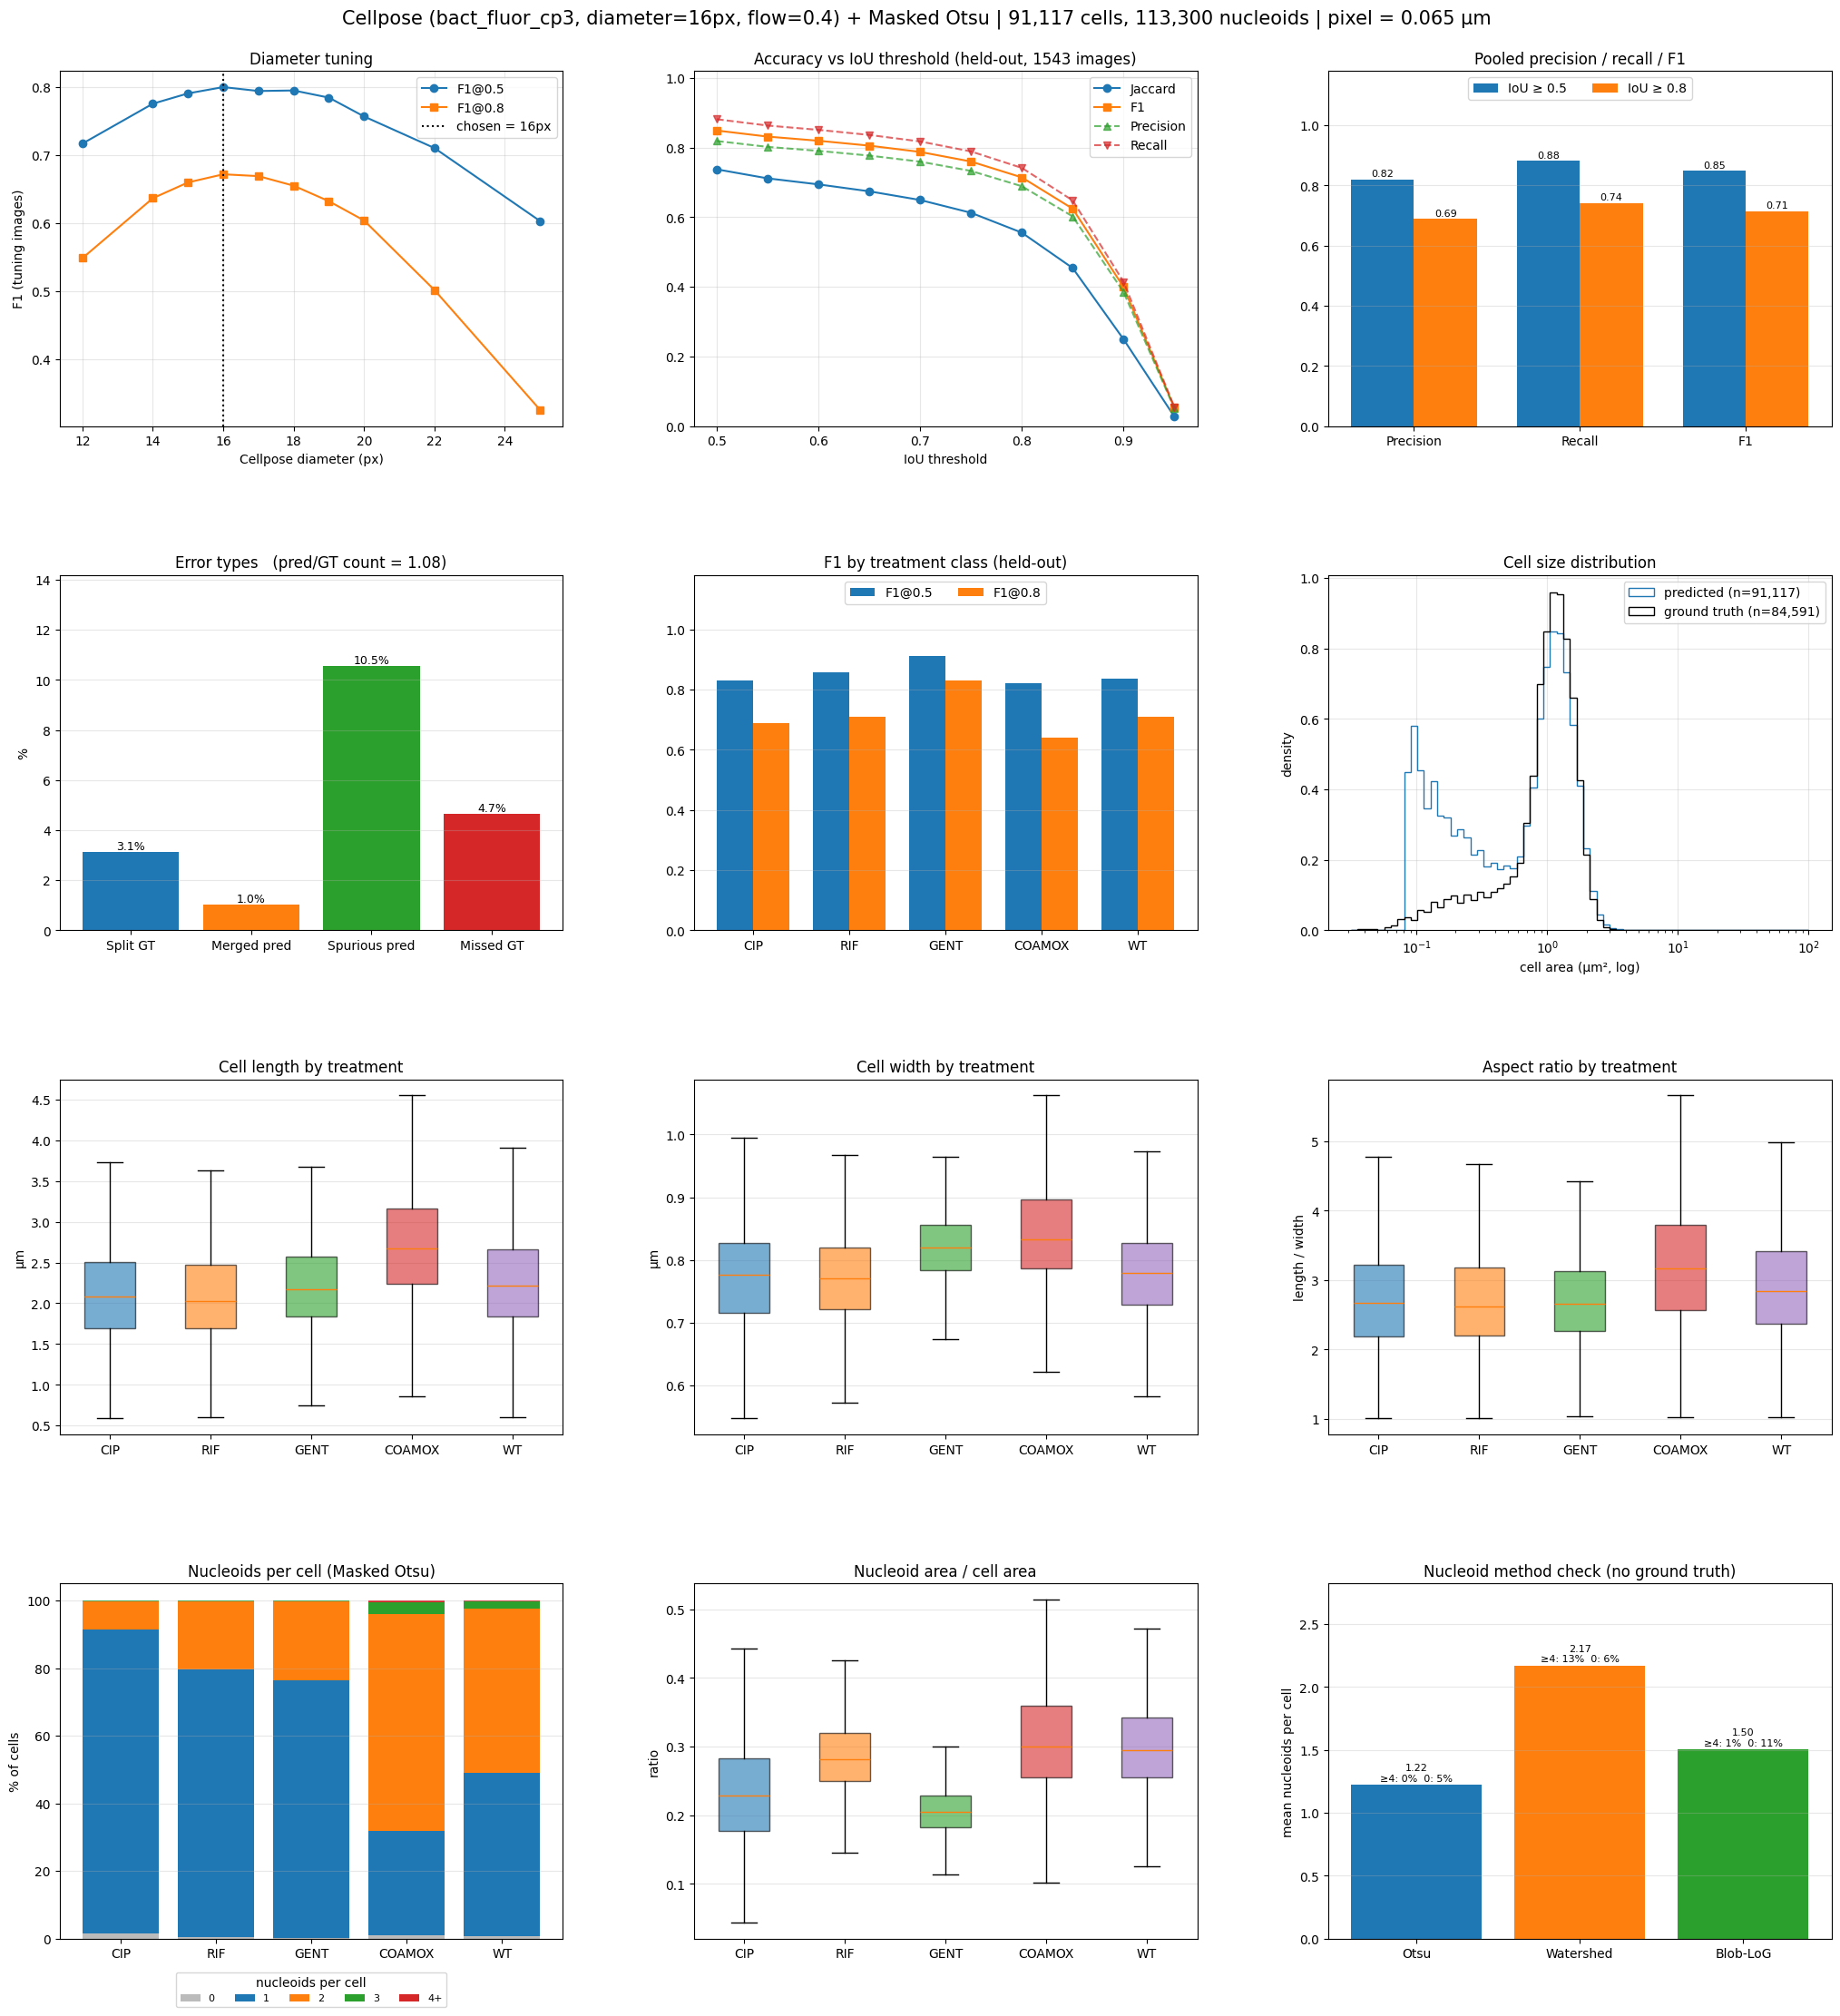

In [62]:
fig = plt.figure(figsize=(21, 23))
gs = fig.add_gridspec(4, 3, hspace=0.42, wspace=0.26, top=0.955, bottom=0.06, left=0.05, right=0.98)
H_ = score_heldout.iloc[0]
ax = fig.add_subplot(gs[0, 0])
if tune_diam_df is not None:
    ax.plot(tune_diam_df.diameter, tune_diam_df["F1@0.5"], "o-", label="F1@0.5")
    ax.plot(tune_diam_df.diameter, tune_diam_df["F1@0.8"], "s-", label="F1@0.8")
    ax.axvline(DIAMETER, color="k", ls=":", label=f"chosen = {DIAMETER}px")
ax.set_xlabel("Cellpose diameter (px)")
ax.set_ylabel("F1 (tuning images)")
ax.set_title("Diameter tuning")
ax.legend()
ax.grid(alpha=0.3)
ax = fig.add_subplot(gs[0, 1])
ax.plot(curve.IoU_Threshold, curve.Jaccard, "o-", label="Jaccard")
ax.plot(curve.IoU_Threshold, curve.F1, "s-", label="F1")
ax.plot(curve.IoU_Threshold, curve.Precision, "^--", label="Precision", alpha=0.7)
ax.plot(curve.IoU_Threshold, curve.Recall, "v--", label="Recall", alpha=0.7)
ax.set_xlabel("IoU threshold")
ax.set_ylim(0, 1.02)
ax.set_title(f"Accuracy vs IoU threshold (held-out, {int(H_.Images)} images)")
ax.legend()
ax.grid(alpha=0.3)
ax = fig.add_subplot(gs[0, 2])
xs = np.arange(3)
w = 0.38
ax.bar(xs - w / 2, [H_["Precision@0.5"], H_["Recall@0.5"], H_["F1@0.5"]], w, label="IoU ≥ 0.5")
ax.bar(xs + w / 2, [H_["Precision@0.8"], H_["Recall@0.8"], H_["F1@0.8"]], w, label="IoU ≥ 0.8")
for i, v in enumerate([H_["Precision@0.5"], H_["Recall@0.5"], H_["F1@0.5"]]):
    ax.text(i - w / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
for i, v in enumerate([H_["Precision@0.8"], H_["Recall@0.8"], H_["F1@0.8"]]):
    ax.text(i + w / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(xs)
ax.set_xticklabels(["Precision", "Recall", "F1"])
ax.set_ylim(0, 1.18)
ax.set_title("Pooled precision / recall / F1")
ax.legend(ncol=2, loc="upper center")
ax.grid(alpha=0.3, axis="y")
ax = fig.add_subplot(gs[1, 0])
errs = ["Split_GT_%", "Merged_Pred_%", "Spurious_Pred_%", "Missed_GT_%"]
b = ax.bar(
    ["Split GT", "Merged pred", "Spurious pred", "Missed GT"],
    [H_[e] for e in errs],
    color=colors[:4],
)
for r_, e in zip(b, errs):
    ax.text(
        r_.get_x() + r_.get_width() / 2,
        r_.get_height() + 0.1,
        f"{H_[e]:.1f}%",
        ha="center",
        fontsize=9,
    )
ax.set_ylim(0, max(H_[e] for e in errs) * 1.25 + 1)
ax.set_ylabel("%")
ax.set_title(f"Error types   (pred/GT count = {H_['Pred/GT']:.2f})")
ax.grid(alpha=0.3, axis="y")
ax = fig.add_subplot(gs[1, 1])
xs = np.arange(len(by_class_scores))
w = 0.38
ax.bar(xs - w / 2, by_class_scores["F1@0.5"], w, label="F1@0.5")
ax.bar(xs + w / 2, by_class_scores["F1@0.8"], w, label="F1@0.8")
ax.set_xticks(xs)
ax.set_xticklabels([c.replace("+ETOH", "") for c in by_class_scores.index])
ax.set_ylim(0, 1.18)
ax.set_title("F1 by treatment class (held-out)")
ax.legend(ncol=2, loc="upper center")
ax.grid(alpha=0.3, axis="y")
ax = fig.add_subplot(gs[1, 2])
bins = np.logspace(-1.5, 2, 70)
ax.hist(
    cells_all.Area_um2,
    bins=bins,
    histtype="step",
    density=True,
    lw=2,
    label=f"predicted (n={len(cells_all):,})",
)
ax.hist(
    gt_areas_all * UM2,
    bins=bins,
    histtype="step",
    density=True,
    lw=2,
    color="k",
    label=f"ground truth (n={len(gt_areas_all):,})",
)
ax.set_xscale("log")
ax.set_xlabel("cell area (µm², log)")
ax.set_ylabel("density")
ax.set_title("Cell size distribution")
ax.legend()
ax.grid(alpha=0.3)
box(fig.add_subplot(gs[2, 0]), qc, "Length_um", "Cell length by treatment", "µm")
box(fig.add_subplot(gs[2, 1]), qc, "Width_um", "Cell width by treatment", "µm")
box(fig.add_subplot(gs[2, 2]), qc, "Aspect_Ratio", "Aspect ratio by treatment", "length / width")
ax = fig.add_subplot(gs[3, 0])
bottom = np.zeros(len(CLASSES))
cats = [
    ("0", lambda s: s == 0),
    ("1", lambda s: s == 1),
    ("2", lambda s: s == 2),
    ("3", lambda s: s == 3),
    ("4+", lambda s: s >= 4),
]
for (lab_, f), col_ in zip(cats, ["#bbbbbb"] + colors[:4]):
    frac = np.array([100 * f(qc.loc[qc.Treatment_Class == c, "Nuc_Count"]).mean() for c in CLASSES])
    ax.bar(short, frac, bottom=bottom, label=lab_, color=col_)
    bottom += frac
ax.set_ylabel("% of cells")
ax.set_title("Nucleoids per cell (Masked Otsu)")
ax.legend(
    title="nucleoids per cell", ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08)
)
ax.grid(alpha=0.3, axis="y")
box(
    fig.add_subplot(gs[3, 1]),
    qc[qc.Nuc_Count > 0],
    "Nuc_Cell_Area_Ratio",
    "Nucleoid area / cell area",
    "ratio",
)
ax = fig.add_subplot(gs[3, 2])
order = ["masked_otsu", "masked_watershed", "blob_log"]
vals = nuc_qc.loc[order, "Mean_Nuc_Per_Cell"]
b = ax.bar(["Otsu", "Watershed", "Blob-LoG"], vals, color=[colors[0], colors[1], colors[2]])
for r_, m_ in zip(b, order):
    ax.text(
        r_.get_x() + r_.get_width() / 2,
        r_.get_height() + 0.03,
        f"{r_.get_height():.2f}\n≥4: {nuc_qc.loc[m_, 'Pct_Cells_4plus_Nuc']:.0f}%  0: {nuc_qc.loc[m_, 'Pct_Cells_0_Nuc']:.0f}%",
        ha="center",
        fontsize=8,
    )
ax.set_ylim(0, max(vals) * 1.3)
ax.set_ylabel("mean nucleoids per cell")
ax.set_title("Nucleoid method check (no ground truth)")
ax.grid(alpha=0.3, axis="y")
fig.suptitle(
    f"Cellpose ({CELLPOSE_MODEL}, diameter={DIAMETER}px, flow={FLOW}) + Masked Otsu | {len(cells_all):,} cells, {len(nucs_all):,} nucleoids | pixel = {PIXEL_SIZE_UM} µm",
    fontsize=15,
    y=0.985,
)
fig.savefig(OUT_ROOT / "figures" / "dashboard.png", dpi=250, bbox_inches="tight")
fig.savefig(OUT_ROOT / "figures" / "dashboard.pdf", bbox_inches="tight")
plt.show()

## **10. Lossless check**

In [63]:
rs = np.random.RandomState(SEED)
sample = cells_all.iloc[rs.choice(len(cells_all), min(60, len(cells_all)), replace=False)]
n_ok = 0
# Index all images in RAW_DIR to avoid KeyError with cached complete runs
src = {p.stem: p for p in RAW_DIR.rglob("*.tif*") if _ok(p)}
zips = {}
for _, r in sample.iterrows():
    if not r.Raw_Crop_Path:
        break
    z = zips.setdefault(r.Crop_Zip, zipfile.ZipFile(OUT_ROOT / "crops" / r.Crop_Zip))
    saved = tifffile.imread(io.BytesIO(z.read(r.Raw_Crop_Path)))
    ref = np.moveaxis(
        load_raw(src[r.Image_ID])[
            int(r.Crop_Y0) : int(r.Crop_Y1), int(r.Crop_X0) : int(r.Crop_X1), :2
        ],
        -1,
        0,
    )
    assert saved.dtype == ref.dtype and np.array_equal(saved, ref), f"MISMATCH: {r.Cell_UID}"
    n_ok += 1
print(
    f"Lossless check passed for {n_ok} / {len(sample)} sampled crops (dtype {ref.dtype}, identical values)."
)

Lossless check passed for 60 / 60 sampled crops (dtype uint16, identical values).


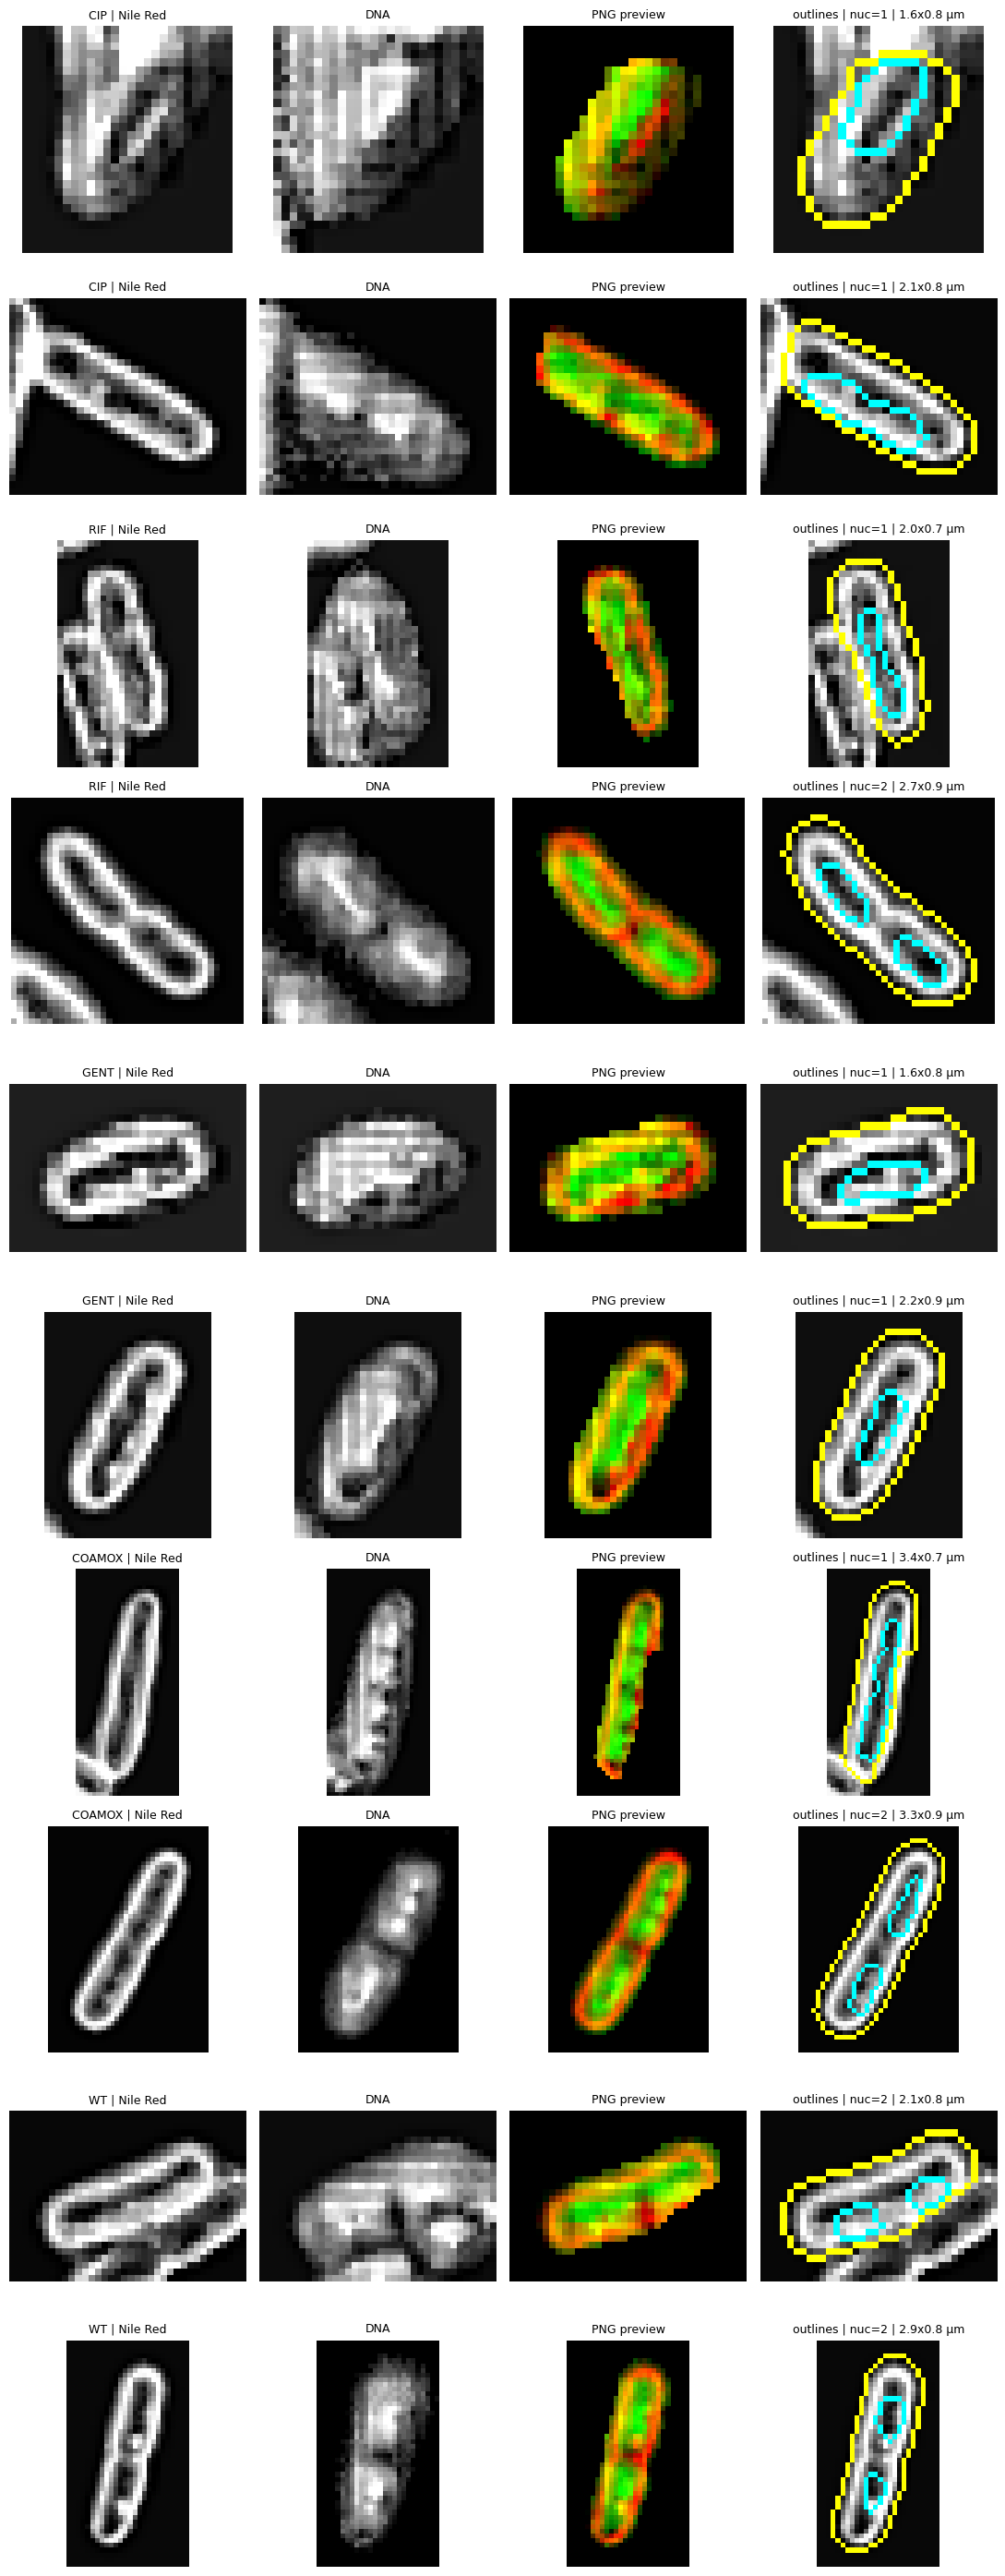

In [64]:
## Sample crops: 2 per class (Nile Red | DNA | saved PNG preview | mask outlines)
N_PER_CLASS = 2
rs = np.random.RandomState(SEED)
zips = {}
fig, axes = plt.subplots(len(CLASSES) * N_PER_CLASS, 4, figsize=(11, 2.8 * len(CLASSES) * N_PER_CLASS))
row = 0
for cls in CLASSES:
    pool = cells_all[(cells_all.Treatment_Class == cls) & cells_all.QC_Pass & (cells_all.Nuc_Count > 0)]
    pick = pool.iloc[rs.choice(len(pool), min(N_PER_CLASS, len(pool)), replace=False)]
    for _, r in pick.iterrows():
        z = zips.setdefault(r.Crop_Zip, zipfile.ZipFile(OUT_ROOT / "crops" / r.Crop_Zip))
        raw = tifffile.imread(io.BytesIO(z.read(r.Raw_Crop_Path)))          # (2, h, w) original dtype
        lab = tifffile.imread(io.BytesIO(z.read(r.Label_Crop_Path)))        # (2, h, w): cell mask, nucleoid labels
        prev = np.array(Image.open(io.BytesIO(z.read(r.Preview_Path))))     # enhanced RGB PNG
        cell = lab[0] > 0
        ax = axes[row]
        ax[0].imshow(enhance_channel(raw[0].astype(np.float32), cell), cmap="gray")
        ax[0].set_title(f"{cls.replace('+ETOH','')} | Nile Red", fontsize=9)
        ax[1].imshow(enhance_channel(raw[1].astype(np.float32), cell), cmap="gray")
        ax[1].set_title("DNA", fontsize=9)
        ax[2].imshow(prev)
        ax[2].set_title("PNG preview", fontsize=9)
        base = np.stack([enhance_channel(raw[0].astype(np.float32), cell)] * 3, -1)
        base[find_boundaries(cell, mode="outer")] = (1, 1, 0)                       # cell outline: yellow
        base[find_boundaries(lab[1] > 0, mode="inner") & cell] = (0, 1, 1)          # nucleoids: cyan
        ax[3].imshow(base)
        ax[3].set_title(f"outlines | nuc={int(r.Nuc_Count)} | {r.Length_um:.1f}x{r.Width_um:.1f} µm", fontsize=9)
        for a in ax:
            a.axis("off")
        row += 1
for k in range(row, len(axes)):
    for a in axes[k]:
        a.axis("off")
plt.tight_layout()
plt.savefig(OUT_ROOT / "figures" / "sample_crops.png", dpi=200, bbox_inches="tight")
plt.show()

## **11. Output inventory**

In [65]:
def folder_size_mb(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 1e6


inv = pd.DataFrame(
    [
        {
            "Folder": d,
            "Files": sum(1 for f in (OUT_ROOT / d).rglob("*") if f.is_file()),
            "Size_MB": round(folder_size_mb(OUT_ROOT / d), 1),
        }
        for d in ["tables", "metrics", "masks", "overlays", "crops", "figures"]
    ]
)
display(inv)
print("All outputs in:", OUT_ROOT)

,Folder,Files,Size_MB
0,tables,14,299.4
1,metrics,24,1.4
2,masks,3136,11.4
3,overlays,1568,484.6
4,crops,5,551.5
5,figures,3,1.1


All outputs in: /content/drive/MyDrive/Research/results_final/cellpose_otsu
